In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/crime-data/2024-12/2024-12-leicestershire-street.csv
/kaggle/input/crime-data/2024-12/2024-12-nottinghamshire-street.csv
/kaggle/input/crime-data/2024-12/2024-12-derbyshire-street.csv
/kaggle/input/crime-data/2023-10/2023-10-derbyshire-street.csv
/kaggle/input/crime-data/2023-10/2023-10-nottinghamshire-street.csv
/kaggle/input/crime-data/2023-10/2023-10-leicestershire-street.csv
/kaggle/input/crime-data/2023-04/2023-04-derbyshire-street.csv
/kaggle/input/crime-data/2023-04/2023-04-nottinghamshire-street.csv
/kaggle/input/crime-data/2023-04/2023-04-leicestershire-street.csv
/kaggle/input/crime-data/2024-07/2024-07-derbyshire-street.csv
/kaggle/input/crime-data/2024-07/2024-07-leicestershire-street.csv
/kaggle/input/crime-data/2024-07/2024-07-nottinghamshire-street.csv
/kaggle/input/crime-data/2023-11/2023-11-leicestershire-street.csv
/kaggle/input/crime-data/2023-11/2023-11-derbyshire-street.csv
/kaggle/input/crime-data/2023-11/2023-11-nottinghamshire-street.csv
/kaggle/in

In [2]:
#initialisng a spark session
!pip install pyspark

from pyspark.sql import SparkSession
spark = SparkSession.builder.appName("CrimeData").getOrCreate()
sc = spark.sparkContext

Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
25/11/14 07:09:43 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


In [3]:
#Loading our data
#enters a subfolder to get to cvs file and load all files into a single dataframe

crime_df = spark.read.csv("/kaggle/input/crime-data/*/*.csv",header=True,inferSchema=True)

#show only 5 rows from our database
crime_df.show(5)
#for data exploration - shows the datatypes associated with each columns 
crime_df.printSchema()



+--------------------+-------------------+--------------------+--------------------+---------+---------+--------------------+---------+-----------------+--------------------+---------------------+-------+
|            Crime ID|              Month|         Reported by|        Falls within|Longitude| Latitude|            Location|LSOA code|        LSOA name|          Crime type|Last outcome category|Context|
+--------------------+-------------------+--------------------+--------------------+---------+---------+--------------------+---------+-----------------+--------------------+---------------------+-------+
|58047a3a95167140d...|2023-05-01 00:00:00|Nottinghamshire P...|Nottinghamshire P...|-1.347639|53.061766|On or near Regent...|E01019444|Amber Valley 003B|Violence and sexu...| Court result unav...|   NULL|
|8ac857a6be54f5424...|2023-05-01 00:00:00|Nottinghamshire P...|Nottinghamshire P...|-1.329102|53.024519|On or near Minkle...|E01019451|Amber Valley 012D|               Drugs| Unabl

In [4]:
#creating a new table called county 
#withColumn is a transformation type 


from pyspark.sql.functions import when, col

#standardises the county names across the dataset by creating a county column 
crime_df = crime_df.withColumn(
    "County",
    when(col("Reported by").like("%Derbyshire%"), "Derbyshire")
     .when(col("Reported by").like("%Leicestershire%"), "Leicestershire")
     .when(col("Reported by").like("%Nottinghamshire%"), "Nottinghamshire")
     .otherwise("None")
)

#distinct() and show() are all examples of actions allows the tranformation to work.
crime_df.select("Reported by", "County").distinct().show()

crime_df.printSchema()
#checks to see whether county has been added to our schema
crime_df.show(5)



+--------------------+---------------+
|         Reported by|         County|
+--------------------+---------------+
|Nottinghamshire P...|Nottinghamshire|
|Derbyshire Consta...|     Derbyshire|
|Leicestershire Po...| Leicestershire|
+--------------------+---------------+

root
 |-- Crime ID: string (nullable = true)
 |-- Month: timestamp (nullable = true)
 |-- Reported by: string (nullable = true)
 |-- Falls within: string (nullable = true)
 |-- Longitude: double (nullable = true)
 |-- Latitude: double (nullable = true)
 |-- Location: string (nullable = true)
 |-- LSOA code: string (nullable = true)
 |-- LSOA name: string (nullable = true)
 |-- Crime type: string (nullable = true)
 |-- Last outcome category: string (nullable = true)
 |-- Context: string (nullable = true)
 |-- County: string (nullable = false)

+--------------------+-------------------+--------------------+--------------------+---------+---------+--------------------+---------+-----------------+--------------------+---

In [5]:
# Rename columns for consistency
crime_df = crime_df.withColumnRenamed('Crime ID', 'Crime_ID')
crime_df = crime_df.withColumnRenamed('Reported by', 'Reported_by')
crime_df = crime_df.withColumnRenamed('Falls within', 'Falls_within')
crime_df = crime_df.withColumnRenamed('LSOA code', 'LSOA_code')
crime_df = crime_df.withColumnRenamed('LSOA name', 'LSOA_name')
crime_df = crime_df.withColumnRenamed('Crime type', 'Crime_type')
crime_df = crime_df.withColumnRenamed('Last outcome category', 'Last_outcome_category')

crime_df.show(5)

                                      

+--------------------+-------------------+--------------------+--------------------+---------+---------+--------------------+---------+-----------------+--------------------+---------------------+-------+---------------+
|            Crime_ID|              Month|         Reported_by|        Falls_within|Longitude| Latitude|            Location|LSOA_code|        LSOA_name|          Crime_type|Last_outcome_category|Context|         County|
+--------------------+-------------------+--------------------+--------------------+---------+---------+--------------------+---------+-----------------+--------------------+---------------------+-------+---------------+
|58047a3a95167140d...|2023-05-01 00:00:00|Nottinghamshire P...|Nottinghamshire P...|-1.347639|53.061766|On or near Regent...|E01019444|Amber Valley 003B|Violence and sexu...| Court result unav...|   NULL|Nottinghamshire|
|8ac857a6be54f5424...|2023-05-01 00:00:00|Nottinghamshire P...|Nottinghamshire P...|-1.329102|53.024519|On or near M

In [6]:
#use the filer to show if all the columns are all there - as i loaded it all in one database

crime_df.select("Reported_by").distinct().show(8)

+--------------------+
|         Reported_by|
+--------------------+
|Derbyshire Consta...|
|Nottinghamshire P...|
|Leicestershire Po...|
+--------------------+



In [7]:
from pyspark.sql.functions import col,sum

crime_df.select([
    sum(col(c).isNull().cast("int")).alias(c)
    for c in crime_df.columns
]).show()

+--------+-----+-----------+------------+---------+--------+--------+---------+---------+----------+---------------------+-------+------+
|Crime_ID|Month|Reported_by|Falls_within|Longitude|Latitude|Location|LSOA_code|LSOA_name|Crime_type|Last_outcome_category|Context|County|
+--------+-----+-----------+------------+---------+--------+--------+---------+---------+----------+---------------------+-------+------+
|  110275|    0|          0|           0|     8746|    8746|       0|     8746|     8746|         0|               110275| 695700|     0|
+--------+-----+-----------+------------+---------+--------+--------+---------+---------+----------+---------------------+-------+------+



In [8]:
from pyspark.sql.functions import col

#groups the columns together
#count gives the number of duplicated rows

crime_df.groupBy(crime_df.columns).count().where(col("count")>1).show()

#removing the duplicated rows 
crime_df = crime_df.dropDuplicates(crime_df.columns)

#the total number of rows after dropping duplicated rows
num_total_rows = crime_df.count()
distinct_rows = crime_df.distinct().count()

#used as a test to see all duplicated rows and it should always give zero if there's no duplication 
duplicate_rows = num_total_rows - distinct_rows

print(f"Total rows after cleaning: {num_total_rows}")
print(f"Unique rows after cleaning: {distinct_rows}")
print(f"Duplicate rows after cleaning: {duplicate_rows}")

if duplicate_rows == 0:
    print(" There are no duplicated rows.")
else:
    print(f"There are still {duplicated_rows} duplicated rows")






+--------------------+-------------------+--------------------+--------------------+---------+---------+--------------------+---------+--------------------+--------------------+---------------------+-------+---------------+-----+
|            Crime_ID|              Month|         Reported_by|        Falls_within|Longitude| Latitude|            Location|LSOA_code|           LSOA_name|          Crime_type|Last_outcome_category|Context|         County|count|
+--------------------+-------------------+--------------------+--------------------+---------+---------+--------------------+---------+--------------------+--------------------+---------------------+-------+---------------+-----+
|                NULL|2023-05-01 00:00:00|Nottinghamshire P...|Nottinghamshire P...|-1.124483|53.360607|On or near Lime T...|E01028001|      Bassetlaw 004A|Anti-social behav...|                 NULL|   NULL|Nottinghamshire|    2|
|                NULL|2023-05-01 00:00:00|Nottinghamshire P...|Nottinghamshire P

Total rows after cleaning: 662022
Unique rows after cleaning: 662022
Duplicate rows after cleaning: 0
 There are no duplicated rows.


In [9]:
#dealing with null values : completely dropped context as it was completely null

crime_df = crime_df.drop("Context")
crime_df.show()

+--------------------+-------------------+--------------------+--------------------+---------+---------+--------------------+---------+--------------+--------------------+---------------------+---------------+
|            Crime_ID|              Month|         Reported_by|        Falls_within|Longitude| Latitude|            Location|LSOA_code|     LSOA_name|          Crime_type|Last_outcome_category|         County|
+--------------------+-------------------+--------------------+--------------------+---------+---------+--------------------+---------+--------------+--------------------+---------------------+---------------+
|66f6a8f164665e13a...|2023-05-01 00:00:00|Nottinghamshire P...|Nottinghamshire P...|-1.261879|53.126713|On or near Superm...|E01027965| Ashfield 005B|         Other theft| Investigation com...|Nottinghamshire|
|569cf47cc6c85c2fa...|2023-05-01 00:00:00|Nottinghamshire P...|Nottinghamshire P...| -1.26225| 53.12234|On or near High P...|E01027976| Ashfield 005E|          

In [10]:
#kepts the nulls in crime_ID
#dealing with the last_outcome_column, lsoas columns 
#kepts the longitude  and latitude the same 

crime_df = crime_df.fillna({
    "LSOA_code": "Unknown",
    "LSOA_name": "Unknown",
    "Last_Outcome_Category": "Pending"
    
})

crime_df.show(10)

+--------------------+-------------------+--------------------+--------------------+---------+---------+--------------------+---------+--------------+--------------------+---------------------+---------------+
|            Crime_ID|              Month|         Reported_by|        Falls_within|Longitude| Latitude|            Location|LSOA_code|     LSOA_name|          Crime_type|Last_outcome_category|         County|
+--------------------+-------------------+--------------------+--------------------+---------+---------+--------------------+---------+--------------+--------------------+---------------------+---------------+
|66f6a8f164665e13a...|2023-05-01 00:00:00|Nottinghamshire P...|Nottinghamshire P...|-1.261879|53.126713|On or near Superm...|E01027965| Ashfield 005B|         Other theft| Investigation com...|Nottinghamshire|
|569cf47cc6c85c2fa...|2023-05-01 00:00:00|Nottinghamshire P...|Nottinghamshire P...| -1.26225| 53.12234|On or near High P...|E01027976| Ashfield 005E|          

In [11]:

#getting the total crime for each county for both the year 2023 & 2024
#select the county column and create a count column called total_num_crime which keeps counts 
#of the total number of crime pair county 

crime_df.createOrReplaceTempView("CrimeData")

spark.sql("""
    SELECT
        County,
        COUNT(*) AS total_num_crime
    FROM CrimeData
    WHERE substring(Month,1,4) IN ('2023', '2024')
    GROUP BY County
    ORDER BY Total_num_crime DESC
""").show()


    

+---------------+---------------+
|         County|total_num_crime|
+---------------+---------------+
|Nottinghamshire|         239592|
| Leicestershire|         213456|
|     Derbyshire|         208974|
+---------------+---------------+



In [12]:
#calculate monthly crime totals for each county


crime_by_county_year_month= spark.sql("""
    SELECT
        County,
        substring(Month,1,4) AS Year,
        substring(Month,6,2) AS Month,
        COUNT(*) AS total_num_crime
    FROM CrimeData
    WHERE substring(Month,1,4) IN ('2023', '2024')
    GROUP BY County,Year,Month
    ORDER BY Year DESC,Month DESC,County;
""")
crime_by_county_year_month.show(60)


#need to save this table for visualisation:
#registers  the temp table 
crime_by_county_year_month.createOrReplaceTempView("CrimeByCountyYearMonth")

+---------------+----+-----+---------------+
|         County|Year|Month|total_num_crime|
+---------------+----+-----+---------------+
|     Derbyshire|2024|   12|           7528|
| Leicestershire|2024|   12|           8043|
|Nottinghamshire|2024|   12|           8779|
|     Derbyshire|2024|   11|           6962|
| Leicestershire|2024|   11|           8666|
|Nottinghamshire|2024|   11|           9355|
|     Derbyshire|2024|   10|           8660|
| Leicestershire|2024|   10|           8934|
|Nottinghamshire|2024|   10|           9704|
|     Derbyshire|2024|   09|           8409|
| Leicestershire|2024|   09|           8956|
|Nottinghamshire|2024|   09|           8796|
|     Derbyshire|2024|   08|           8803|
| Leicestershire|2024|   08|           9032|
|Nottinghamshire|2024|   08|          10144|
|     Derbyshire|2024|   07|           9116|
| Leicestershire|2024|   07|           9240|
|Nottinghamshire|2024|   07|          10729|
|     Derbyshire|2024|   06|           9197|
| Leiceste

In [13]:
#task 3 - calculating the frequency for the  crime type for each county 

spark.sql("""
    SELECT
        County,
        Crime_type,
        COUNT(*) AS crime_frequency
    FROM CrimeData
    GROUP BY County,Crime_type
    ORDER BY County ASC, crime_frequency DESC
""").show(60)


    

+---------------+--------------------+---------------+
|         County|          Crime_type|crime_frequency|
+---------------+--------------------+---------------+
|     Derbyshire|Violence and sexu...|          85804|
|     Derbyshire|Anti-social behav...|          25186|
|     Derbyshire|        Public order|          21518|
|     Derbyshire|Criminal damage a...|          16416|
|     Derbyshire|         Other theft|          14375|
|     Derbyshire|         Shoplifting|          13826|
|     Derbyshire|       Vehicle crime|           8795|
|     Derbyshire|            Burglary|           7541|
|     Derbyshire|               Drugs|           5410|
|     Derbyshire|         Other crime|           4335|
|     Derbyshire|Possession of wea...|           2010|
|     Derbyshire|             Robbery|           1341|
|     Derbyshire|Theft from the pe...|           1265|
|     Derbyshire|       Bicycle theft|           1152|
| Leicestershire|Violence and sexu...|          81604|
| Leiceste

In [14]:

 #Converion of the  spark dataFrame to pandas dataframe to use pandas visualisations  methods 
pd_df = crime_by_county_year_month.toPandas()


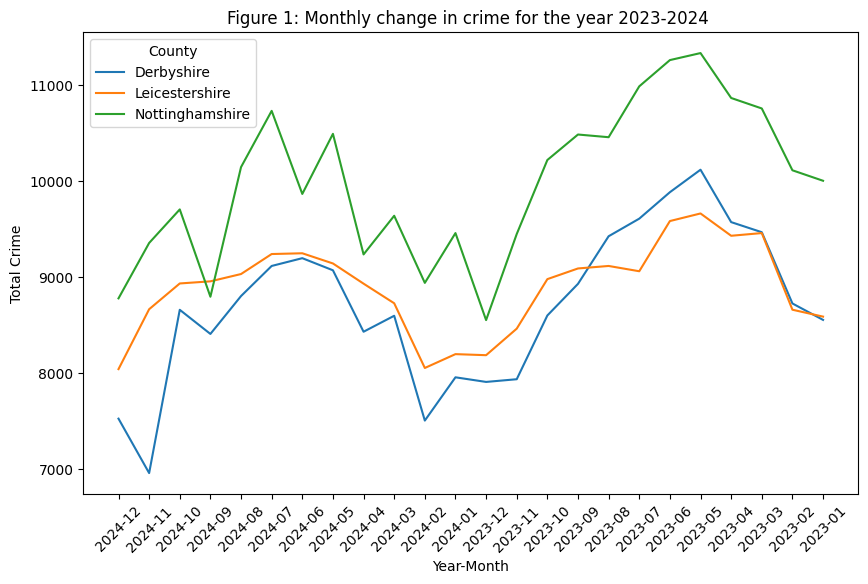

In [15]:
import matplotlib.pyplot as plt

#plotting the line graph
plt.figure(figsize=(10,6))
for county,group in pd_df.groupby('County'):
    plt.plot(
        group['Year'] + "-" +group['Month'],
        group['total_num_crime'],
        label=county
    )

#for style and layout

plt.title("Figure 1: Monthly change in crime for the year 2023-2024 ")
plt.xlabel("Year-Month")
plt.ylabel("Total Crime")
plt.legend(title="County")
plt.xticks(rotation =45)
plt.show()

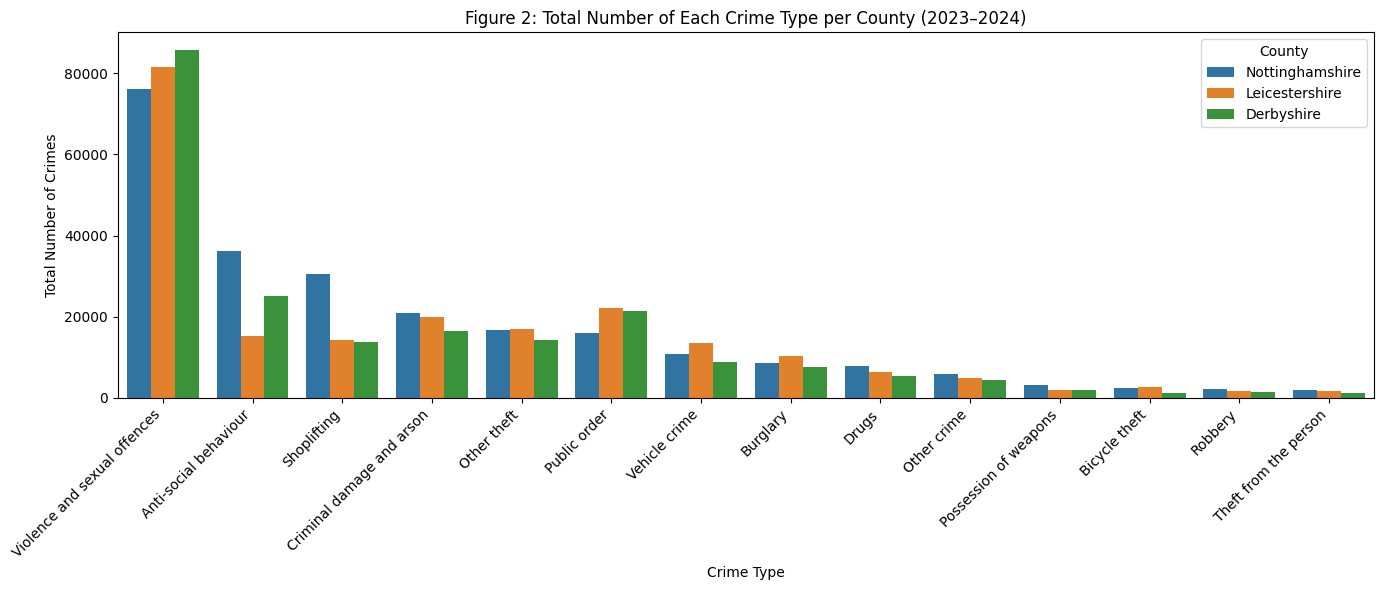

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns  # handles grouped bars easily
from pyspark.sql.functions import substring, col, count

# Filter to 2023–2024
df_crime_filtered = crime_df.filter(
    substring(col("Month"), 1, 4).isin("2023", "2024")
)

# Group by County and Crime Type
df_crime_grouped = (
    df_crime_filtered
    .groupBy("County", "Crime_type")
    .agg(count("*").alias("total_num_crime"))
    .orderBy("County", "total_num_crime", ascending=False)
    .toPandas()
)

# Plot grouped bar chart directly
plt.figure(figsize=(14, 6))
sns.barplot(
    data=df_crime_grouped,
    x="Crime_type",
    y="total_num_crime",
    hue="County"   
)

# Style and labels
plt.title("Figure 2: Total Number of Each Crime Type per County (2023–2024)")
plt.xlabel("Crime Type")
plt.ylabel("Total Number of Crimes")
plt.xticks(rotation=45, ha="right")
plt.legend(title="County")
plt.tight_layout()
plt.show()




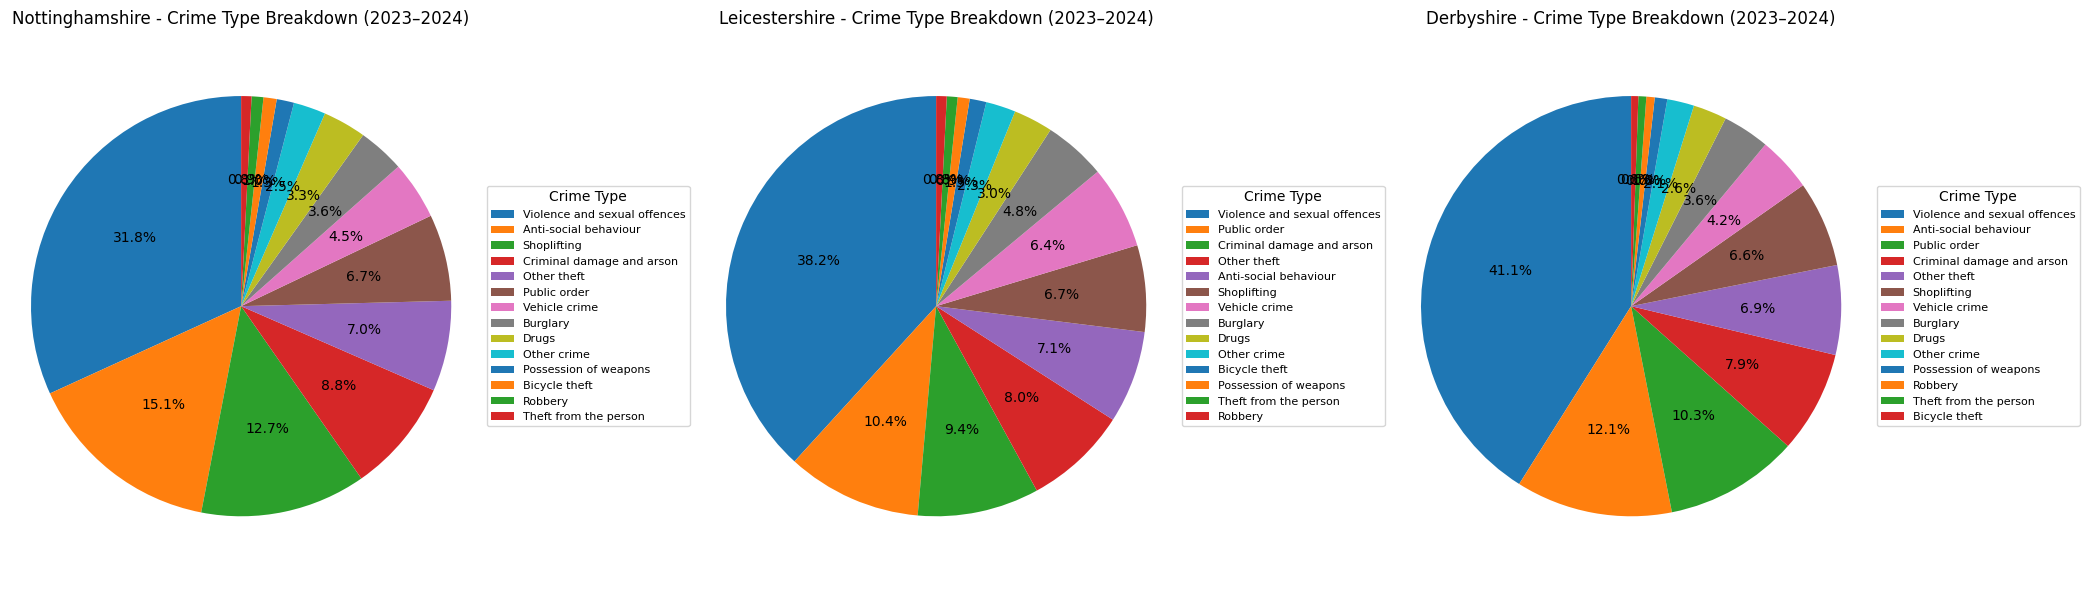

In [17]:
import matplotlib.pyplot as plt
from pyspark.sql.functions import substring, col, count

#  Filter dataset to only include crimes from 2023 and 2024
df_crime_filtered = crime_df.filter(substring(col("Month"), 1, 4).isin("2023", "2024"))

#  Group the filtered data by County and Crime_type, and count total crimes
df_crime_grouped = (
    df_crime_filtered
    .groupBy("County", "Crime_type")
    .agg(count("*").alias("total_num_crime"))
    .orderBy("County", "total_num_crime", ascending=False)
    .toPandas()
)

#  Create one pie chart per county
counties = df_crime_grouped["County"].unique()

# Adjust width based on number of counties


plt.figure(figsize=(7* len(counties), 6)) 

i = 1
for county in counties:
    plt.subplot(1, len(counties), i)
    county_data = df_crime_grouped[df_crime_grouped["County"] == county]
    
    # Create pie chart without text labels 
    wedges, texts, autotexts = plt.pie(
        county_data["total_num_crime"],
        labels=None,           #  No labels around the pie
        autopct="%1.1f%%",     # Keep percentage values
        startangle=90,
        radius=1.0
    )

    # Add a title for each subplot
    plt.title(f"{county} - Crime Type Breakdown (2023–2024)")

    # Keep pie chart circular
    plt.axis("equal")

    # Add a legend for crime types
    plt.legend(
        wedges,                              
        county_data["Crime_type"],            
        title="Crime Type",
        loc="center left",                    
        bbox_to_anchor=(1.02, 0.5),           
        fontsize=8
    )

    i += 1  # Move to next subplot

#  Adjust spacing and display
plt.tight_layout()
plt.show()

